# Chimera Alpha Biology Analysis

Per-gene integration coefficient (alpha) analysis from the MMD-enhanced model.

- **alpha**: per-gene integration coefficient in (0, 1). High alpha = conserved (shared pathway fits), low = divergent (residual needed).
- **delta_alpha = alpha - conservation_prior**: learned correction. Positive = more conserved in expression than sequence suggests. Negative = more divergent.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 150

adata = ad.read_h5ad('../data/processed/camex_human_monkey.h5ad')
state = np.load('../training/runs/iter31-mmd1k-masked-detached/final_state.npz')
alpha = state['alpha']
prior = state['prior']
delta_alpha = alpha - prior
correction = state['correction']
S_g = state['S_g_ema']
residual_rms = state['residual_rms']

gene_names = adata.var_names.values
print(f'{len(alpha)} genes, alpha range: [{alpha.min():.3f}, {alpha.max():.3f}]')
print(f'Delta-alpha: {(delta_alpha > 0).mean():.1%} positive, {(delta_alpha < 0).mean():.1%} negative')

8430 genes, alpha range: [0.135, 0.976]
Delta-alpha: 37.6% positive, 62.4% negative


## 1. Alpha Distribution and Prior Comparison

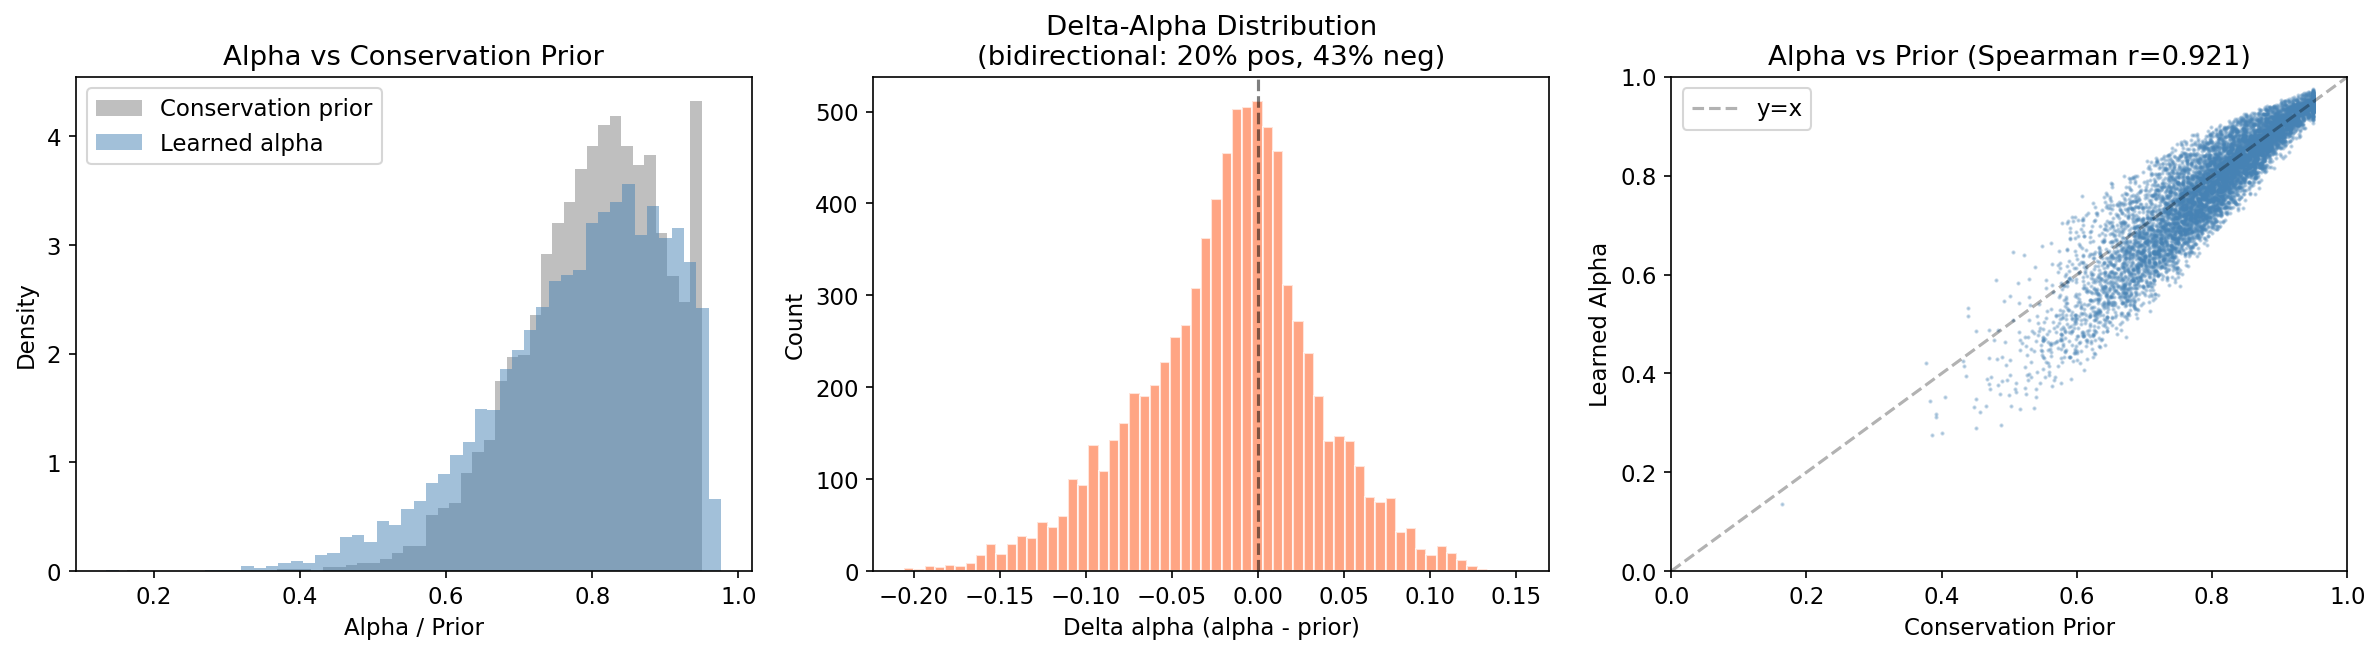

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Alpha histogram with prior overlay
ax = axes[0]
ax.hist(prior, bins=50, alpha=0.5, color='gray', label='Conservation prior', density=True)
ax.hist(alpha, bins=50, alpha=0.5, color='steelblue', label='Learned alpha', density=True)
ax.set_xlabel('Alpha / Prior')
ax.set_ylabel('Density')
ax.set_title('Alpha vs Conservation Prior')
ax.legend()

# Delta-alpha distribution
ax = axes[1]
ax.hist(delta_alpha, bins=60, color='coral', alpha=0.7, edgecolor='white')
ax.axvline(0, color='black', linestyle='--', alpha=0.5)
ax.set_xlabel('Delta alpha (alpha - prior)')
ax.set_ylabel('Count')
ax.set_title(f'Delta-Alpha Distribution\n(bidirectional: {(delta_alpha>0.02).mean():.0%} pos, {(delta_alpha<-0.02).mean():.0%} neg)')

# Alpha vs prior scatter
ax = axes[2]
r, _ = spearmanr(prior, alpha)
ax.scatter(prior, alpha, s=1, alpha=0.3, c='steelblue', rasterized=True)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='y=x')
ax.set_xlabel('Conservation Prior')
ax.set_ylabel('Learned Alpha')
ax.set_title(f'Alpha vs Prior (Spearman r={r:.3f})')
ax.legend()
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 2. L-Shape: Residual Magnitude vs Alpha

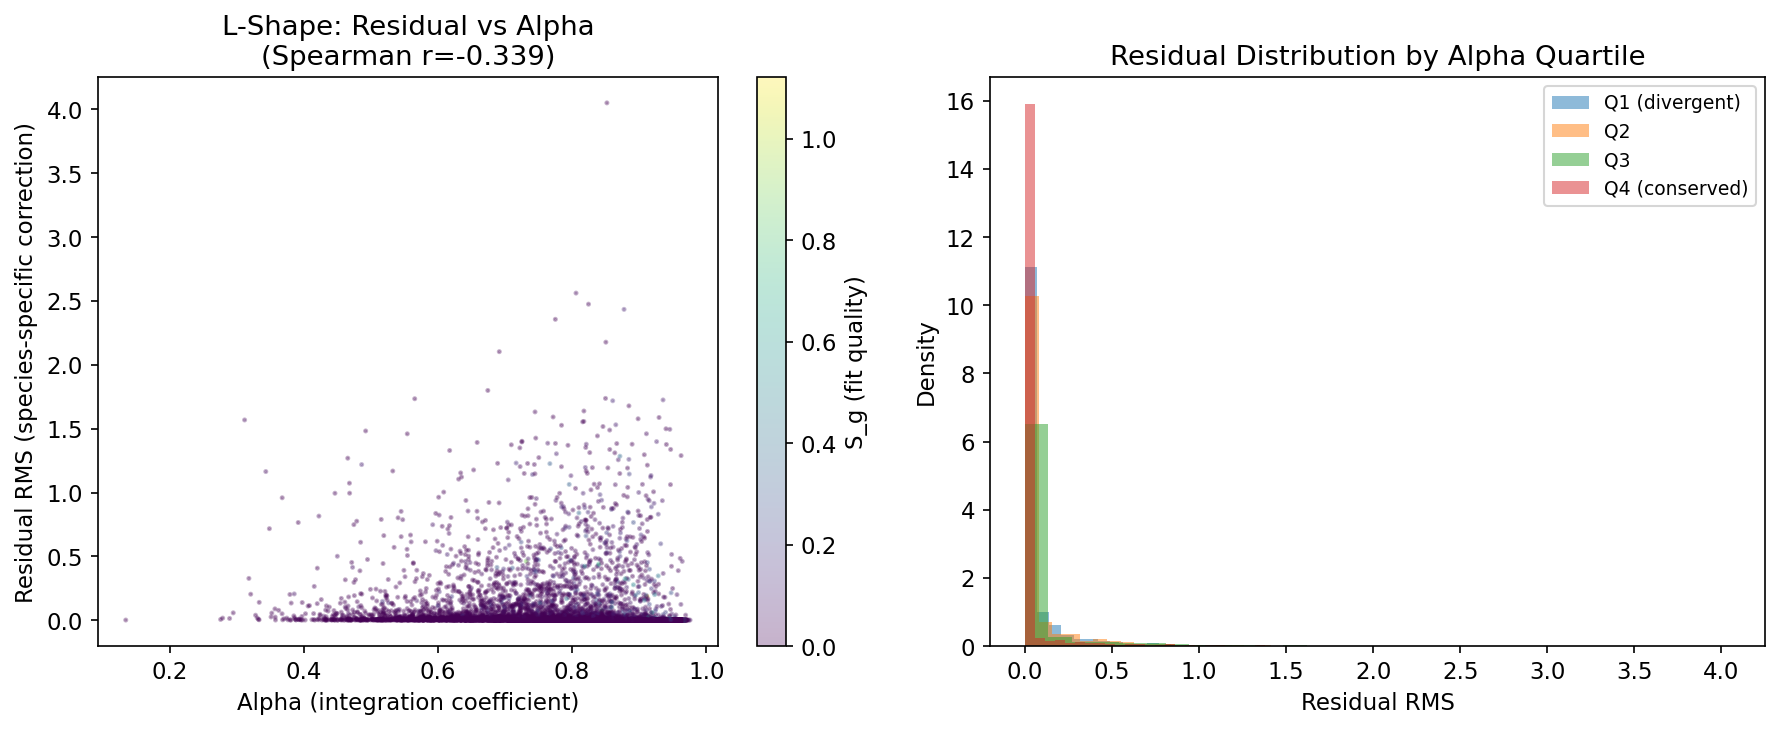

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# L-shape scatter
ax = axes[0]
r_ls, _ = spearmanr(alpha, residual_rms)
sc = ax.scatter(alpha, residual_rms, s=2, alpha=0.3, c=S_g, cmap='viridis', rasterized=True)
plt.colorbar(sc, ax=ax, label='S_g (fit quality)')
ax.set_xlabel('Alpha (integration coefficient)')
ax.set_ylabel('Residual RMS (species-specific correction)')
ax.set_title(f'L-Shape: Residual vs Alpha\n(Spearman r={r_ls:.3f})')

# Alpha by quartile analysis
ax = axes[1]
quartiles = np.quantile(alpha, [0.25, 0.5, 0.75])
q_labels = ['Q1 (divergent)', 'Q2', 'Q3', 'Q4 (conserved)']
q_idx = np.digitize(alpha, quartiles)
for qi in range(4):
    mask = q_idx == qi
    ax.hist(residual_rms[mask], bins=30, alpha=0.5, label=q_labels[qi], density=True)
ax.set_xlabel('Residual RMS')
ax.set_ylabel('Density')
ax.set_title('Residual Distribution by Alpha Quartile')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 3. Top and Bottom Genes by Delta-Alpha

In [4]:
# Top 20 genes with highest positive delta-alpha (more conserved than prior)
top_idx = np.argsort(delta_alpha)[::-1][:20]
print('Top 20 genes with HIGHEST delta-alpha (more conserved in expression than sequence):')
print(f'{"Gene":<20} {"Alpha":>8} {"Prior":>8} {"Delta":>8} {"Residual":>10} {"S_g":>8}')
print('-' * 60)
for i in top_idx:
    print(f'{gene_names[i]:<20} {alpha[i]:>8.3f} {prior[i]:>8.3f} {delta_alpha[i]:>8.3f} {residual_rms[i]:>10.4f} {S_g[i]:>8.3f}')

print()

# Bottom 20 genes with most negative delta-alpha (more divergent than prior)
bot_idx = np.argsort(delta_alpha)[:20]
print('Top 20 genes with LOWEST delta-alpha (more divergent in expression than sequence):')
print(f'{"Gene":<20} {"Alpha":>8} {"Prior":>8} {"Delta":>8} {"Residual":>10} {"S_g":>8}')
print('-' * 60)
for i in bot_idx:
    print(f'{gene_names[i]:<20} {alpha[i]:>8.3f} {prior[i]:>8.3f} {delta_alpha[i]:>8.3f} {residual_rms[i]:>10.4f} {S_g[i]:>8.3f}')

Top 20 genes with HIGHEST delta-alpha (more conserved in expression than sequence):
Gene                    Alpha    Prior    Delta   Residual      S_g
------------------------------------------------------------
ortho_970               0.758    0.607    0.151     0.0118    0.000
ortho_933               0.646    0.506    0.140     0.0310    0.006
ortho_5510              0.786    0.651    0.135     0.3420    0.088
ortho_3595              0.783    0.652    0.131     0.0098    0.000
ortho_5219              0.800    0.670    0.130     0.0047    0.000
ortho_6101              0.830    0.703    0.127     0.0520    0.051
ortho_8633              0.704    0.578    0.125     0.0160    0.000
ortho_3589              0.717    0.592    0.125     0.0079    0.000
ortho_1987              0.776    0.651    0.125     0.0011    0.000
ortho_6142              0.766    0.643    0.122     0.0021    0.000
ortho_5050              0.708    0.587    0.121     0.0013    0.000
ortho_5986              0.744    0.624 

## 4. Alpha by Expression Level

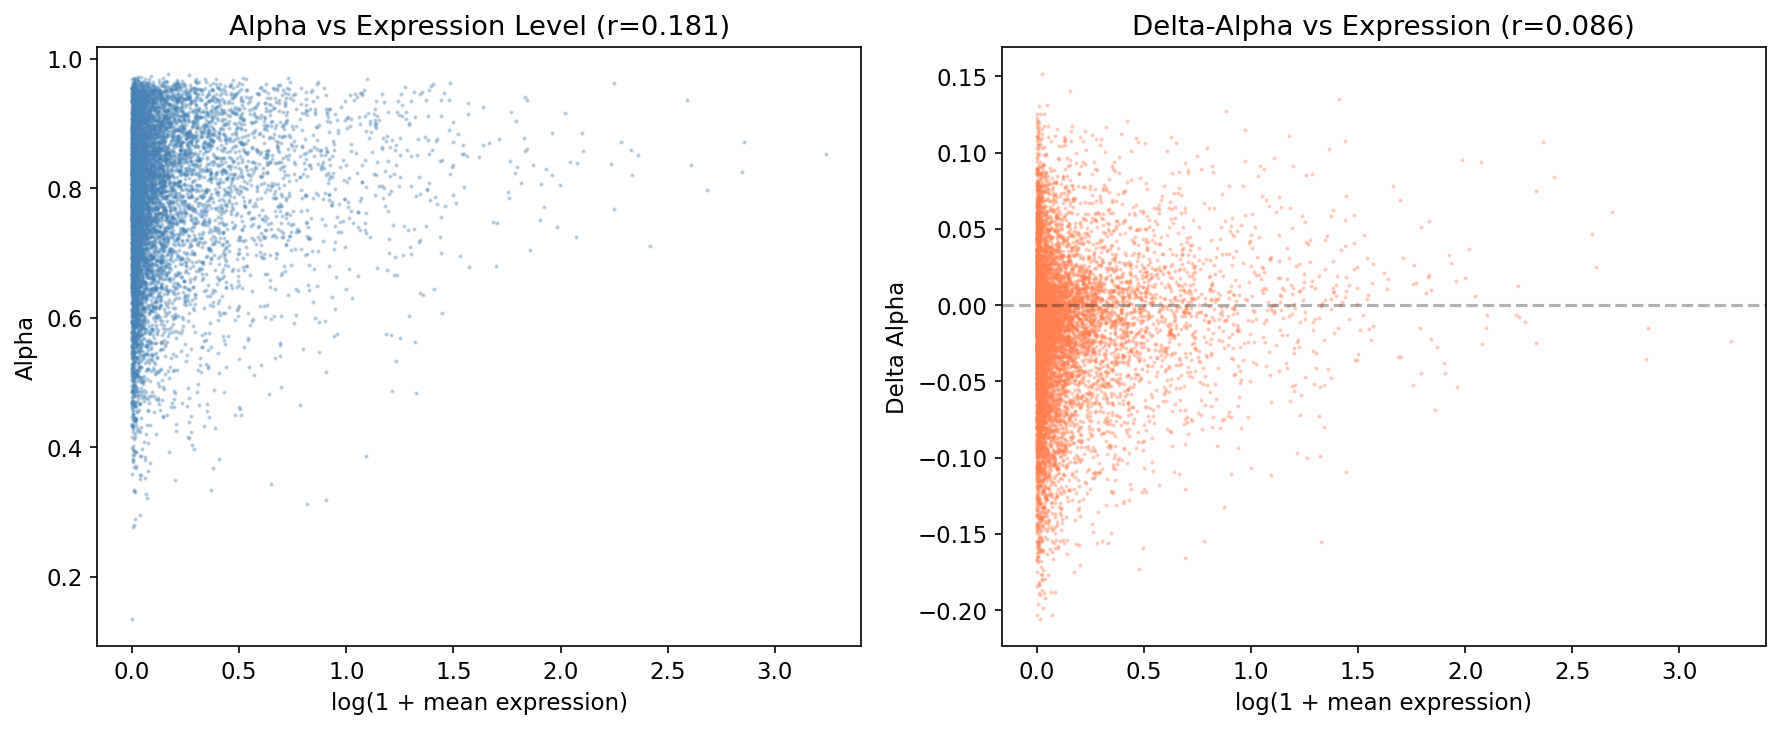

In [5]:
import scipy.sparse as sp_mod

X = adata.X
if sp_mod.issparse(X):
    mean_expr = np.asarray(X.mean(0)).ravel()
else:
    mean_expr = X.mean(0)

log_mean = np.log1p(mean_expr)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
r_expr, _ = spearmanr(log_mean, alpha)
ax.scatter(log_mean, alpha, s=1, alpha=0.3, c='steelblue', rasterized=True)
ax.set_xlabel('log(1 + mean expression)')
ax.set_ylabel('Alpha')
ax.set_title(f'Alpha vs Expression Level (r={r_expr:.3f})')

ax = axes[1]
r_dexpr, _ = spearmanr(log_mean, delta_alpha)
ax.scatter(log_mean, delta_alpha, s=1, alpha=0.3, c='coral', rasterized=True)
ax.axhline(0, color='black', linestyle='--', alpha=0.3)
ax.set_xlabel('log(1 + mean expression)')
ax.set_ylabel('Delta Alpha')
ax.set_title(f'Delta-Alpha vs Expression (r={r_dexpr:.3f})')

plt.tight_layout()
plt.show()

## 5. Cross-Species Expression Correlation by Alpha Quartile

/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_22110/1135311250.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=q_labels, patch_artist=True,


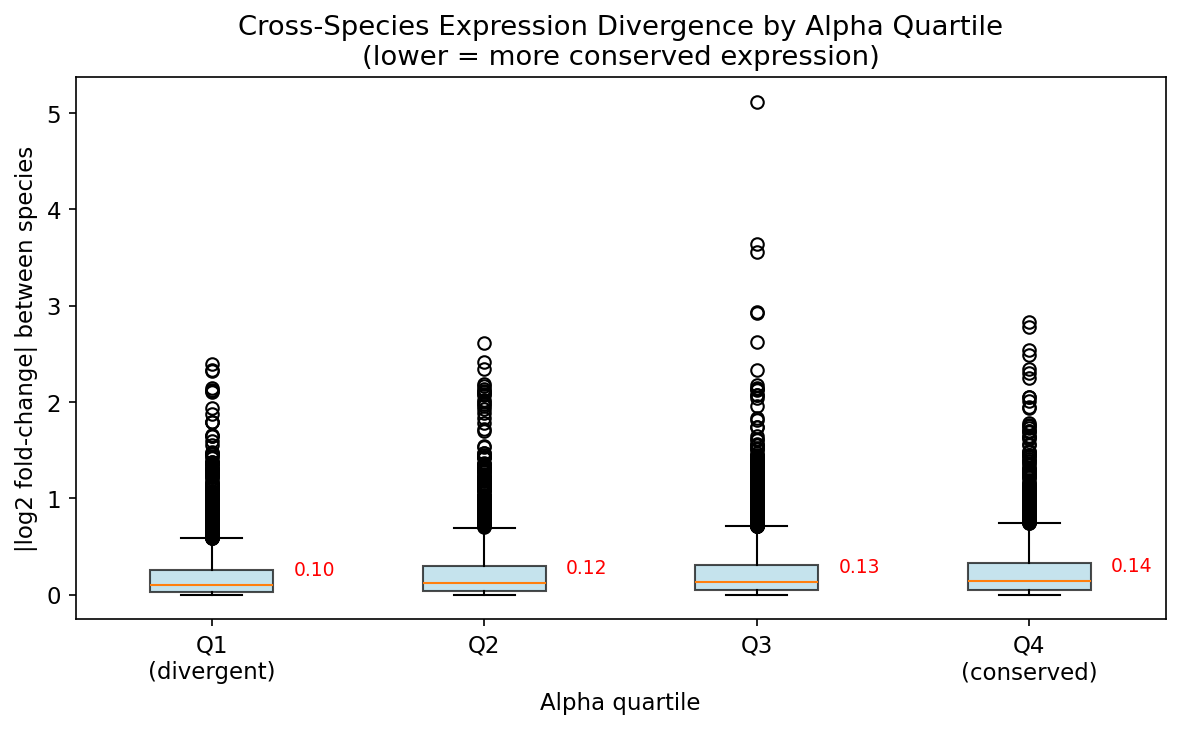

Alpha vs |LFC|: Spearman r=0.078, p=9.50e-13
Negative r confirms: high-alpha genes have smaller cross-species expression differences


In [6]:
# Compute per-gene cross-species expression correlation
X_dense = X.toarray() if sp_mod.issparse(X) else np.asarray(X)
sp_labels = state['species_labels']

# Per-species mean expression (library-size normalized)
lib = X_dense.sum(axis=1, keepdims=True).clip(min=1)
frac = X_dense / lib

mean_sp0 = np.log1p(1e4 * frac[sp_labels == 0].mean(0))
mean_sp1 = np.log1p(1e4 * frac[sp_labels == 1].mean(0))

# Cross-species correlation per gene (using rank)
# Actually, use per-gene scalar: |log-fold-change|
lfc = np.abs(mean_sp0 - mean_sp1)

# Group by alpha quartile
fig, ax = plt.subplots(figsize=(8, 5))
quartiles = np.quantile(alpha, [0.25, 0.5, 0.75])
q_idx = np.digitize(alpha, quartiles)
q_labels = ['Q1\n(divergent)', 'Q2', 'Q3', 'Q4\n(conserved)']

data = [lfc[q_idx == qi] for qi in range(4)]
bp = ax.boxplot(data, labels=q_labels, patch_artist=True,
                boxprops=dict(facecolor='lightblue', alpha=0.7))
ax.set_ylabel('|log2 fold-change| between species')
ax.set_xlabel('Alpha quartile')
ax.set_title('Cross-Species Expression Divergence by Alpha Quartile\n(lower = more conserved expression)')

# Add median annotations
for qi in range(4):
    med = np.median(data[qi])
    ax.annotate(f'{med:.2f}', xy=(qi+1, med), xytext=(qi+1.3, med+0.1),
                fontsize=9, color='red')

plt.tight_layout()
plt.show()

# Spearman correlation between alpha and cross-species fold-change
r, p = spearmanr(alpha, lfc)
print(f'Alpha vs |LFC|: Spearman r={r:.3f}, p={p:.2e}')
print('Negative r confirms: high-alpha genes have smaller cross-species expression differences')

## 6. FQR Signal (S_g) Analysis

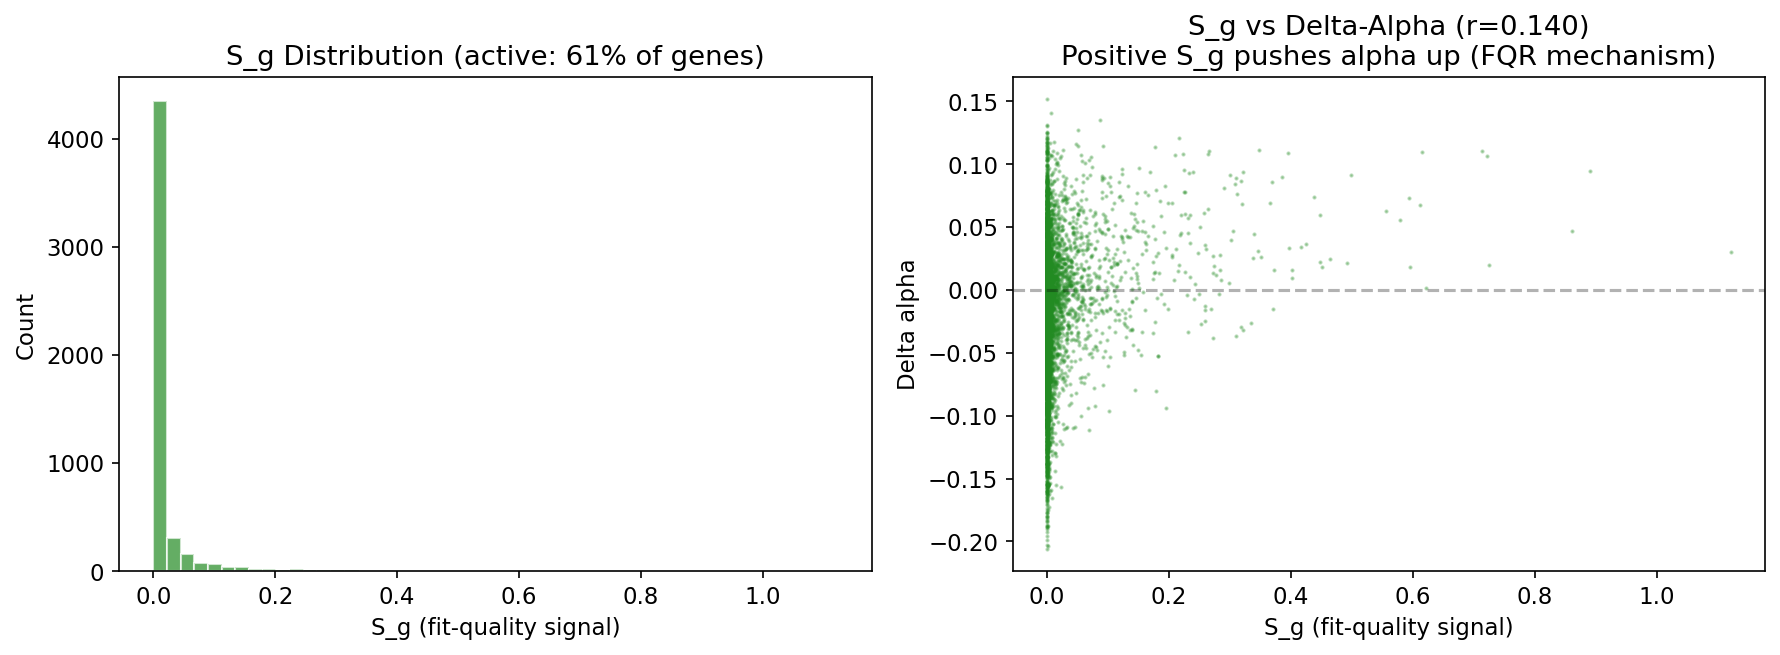

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.hist(S_g[S_g > 0], bins=50, color='forestgreen', alpha=0.7, edgecolor='white')
ax.set_xlabel('S_g (fit-quality signal)')
ax.set_ylabel('Count')
ax.set_title(f'S_g Distribution (active: {(S_g > 0).mean():.0%} of genes)')

ax = axes[1]
ax.scatter(S_g, delta_alpha, s=1, alpha=0.3, c='forestgreen', rasterized=True)
ax.axhline(0, color='black', linestyle='--', alpha=0.3)
ax.set_xlabel('S_g (fit-quality signal)')
ax.set_ylabel('Delta alpha')
r_sg, _ = spearmanr(S_g, delta_alpha)
ax.set_title(f'S_g vs Delta-Alpha (r={r_sg:.3f})\nPositive S_g pushes alpha up (FQR mechanism)')

plt.tight_layout()
plt.show()